# CrafterDojo Tutorial: CrafterPlay & CrafterCaption

This notebook demonstrates how to work with **CrafterPlay** (raw play data) and
**CrafterCaption** (caption annotations), the two datasets released by CrafterDojo:

- **Part 1 — Loading**: self-contained loader functions for every field (no dependency on the
  training codebase).
- **Part 2 — Trajectory visualization**: video frames, symbolic map, vitals, achievements, and
  caption timelines.
- **Part 3 — Working with full-record shards**: stream a single episode out of a `.tar.zst`
  shard without extracting it.

`docs/dataset/GENERATION.md` walks through generating custom data with the CrafterDojo
toolkits; `docs/dataset/DATASET.md` has the full format specification and dataset statistics.

## Setup

1. Install `numpy`, `matplotlib`, `imageio[ffmpeg]`, and (for Part 3) `zstandard` — or simply
   install the project environment from the repository root (`uv sync`, or `pip install -e .`).
2. Download the dataset, keeping its directory structure
   (`<split>/Craftax-Classic-Symbolic-v1/<field>/...`).
3. Point `CRAFTERDOJO_DATA_ROOT` at the directory that contains the split directories, or place
   it at `<repo>/data`.

In [1]:
import os, pickle, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")  # silence third-party deprecation chatter

# Locate the repository root (the directory containing pyproject.toml).
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

# Where the downloaded dataset lives (the directory containing the split directories).
DATA_ROOT = Path(os.environ.get("CRAFTERDOJO_DATA_ROOT", REPO_ROOT / "data"))

SPLIT = "gatherer-10B"          # or "survival-10B"
EPISODE = "00000"               # any episode id present in the download
EP_DIR = DATA_ROOT / SPLIT / "Craftax-Classic-Symbolic-v1"
assert EP_DIR.exists(), (
    "Dataset not found - set the CRAFTERDOJO_DATA_ROOT environment variable to the "
    "directory that contains the downloaded split directories."
)
print(f"using split={SPLIT}, episode={EPISODE}")


using split=gatherer-10B, episode=00000


## Part 1 — Loading the data

Each episode consists of five files (see Section 4 of `DATASET.md` for the full spec):

| Field | File | Format |
|---|---|---|
| length | `len/len_<id>.txt` | plain int `T` |
| actions | `action/action_<id>.pkl` | pickle: `(action_ids int32[T], is_null bool[T], is_sleeping bool[T])` |
| state | `state/episode_<id>.npz` | 50 named numpy arrays (symbolic env state, `T+1` steps) |
| captions | `caption/episode_<id>.pkl` | pickle: list of `((start_frame, end_frame), text, rule)` |
| video | `video/video_<id>.mp4` | 144x144 MP4, `T+1` frames |

The loaders below are fully standalone — copy-paste them into your own project.

In [2]:
import imageio.v2 as imageio


def load_len(root, ep):
    """Episode length T (number of actions)."""
    return int((Path(root) / "len" / f"len_{ep}.txt").read_text())


def load_actions(root, ep):
    """Returns (action_ids int32[T], is_null bool[T], is_sleeping bool[T])."""
    with open(Path(root) / "action" / f"action_{ep}.pkl", "rb") as f:
        action_ids, is_null, is_sleeping = pickle.load(f)
    return action_ids, is_null, is_sleeping


def load_state(root, ep):
    """Symbolic state: NpzFile with 50 named arrays (lazy; index by key)."""
    return np.load(Path(root) / "state" / f"episode_{ep}.npz")


def load_captions(root, ep):
    """CrafterCaption annotations: list of ((start_frame, end_frame), text, rule_name)."""
    with open(Path(root) / "caption" / f"episode_{ep}.pkl", "rb") as f:
        return pickle.load(f)


def video_path(root, ep):
    return Path(root) / "video" / f"video_{ep}.mp4"


def count_video_frames(path):
    reader = imageio.get_reader(str(path))
    n = reader.count_frames()
    reader.close()
    return n


def load_video_frames(path, indices=None, max_frames=None):
    """Load frames as uint8 array (N, 144, 144, 3).

    indices: exact frame indices to fetch (random access).
    max_frames: read sequentially up to this many frames.
    """
    reader = imageio.get_reader(str(path))
    if indices is not None:
        frames = [reader.get_data(int(i)) for i in indices]
    else:
        frames = []
        for i, frame in enumerate(reader):
            if max_frames is not None and i >= max_frames:
                break
            frames.append(frame)
    reader.close()
    return np.stack(frames)

In [3]:
T = load_len(EP_DIR, EPISODE)
action_ids, is_null, is_sleeping = load_actions(EP_DIR, EPISODE)
state = load_state(EP_DIR, EPISODE)
captions = load_captions(EP_DIR, EPISODE)
n_frames = count_video_frames(video_path(EP_DIR, EPISODE))

print(f"episode length T          : {T}")
print(f"actions                   : {action_ids.shape} {action_ids.dtype} "
      f"(null={is_null.mean():.1%}, sleeping={is_sleeping.mean():.1%})")
print(f"state arrays              : {len(state.files)} named arrays")
print(f"  map                     : {state['map'].shape} {state['map'].dtype}")
print(f"  achievements            : {state['achievements'].shape} {state['achievements'].dtype}")
print(f"captions                  : {len(captions)} segments")
for c in captions[:3]:
    print(f"  - {c}")
print(f"video frames              : {n_frames} (= T + 1)")

episode length T          : 10000
actions                   : (10000,) int32 (null=35.3%, sleeping=22.1%)
state arrays              : 50 named arrays


  map                     : (10001, 64, 64) int32
  achievements            : (10001, 22) bool
captions                  : 5298 segments
  - ((2, 8), 'obtain sapling', 'Harvest')
  - ((3, 9), 'place sapling on grass', 'Construct')
  - ((6, 12), 'obtain tree', 'Harvest')
video frames              : 10001 (= T + 1)


## Part 2 — Trajectory visualization

### 2.1 Video frames

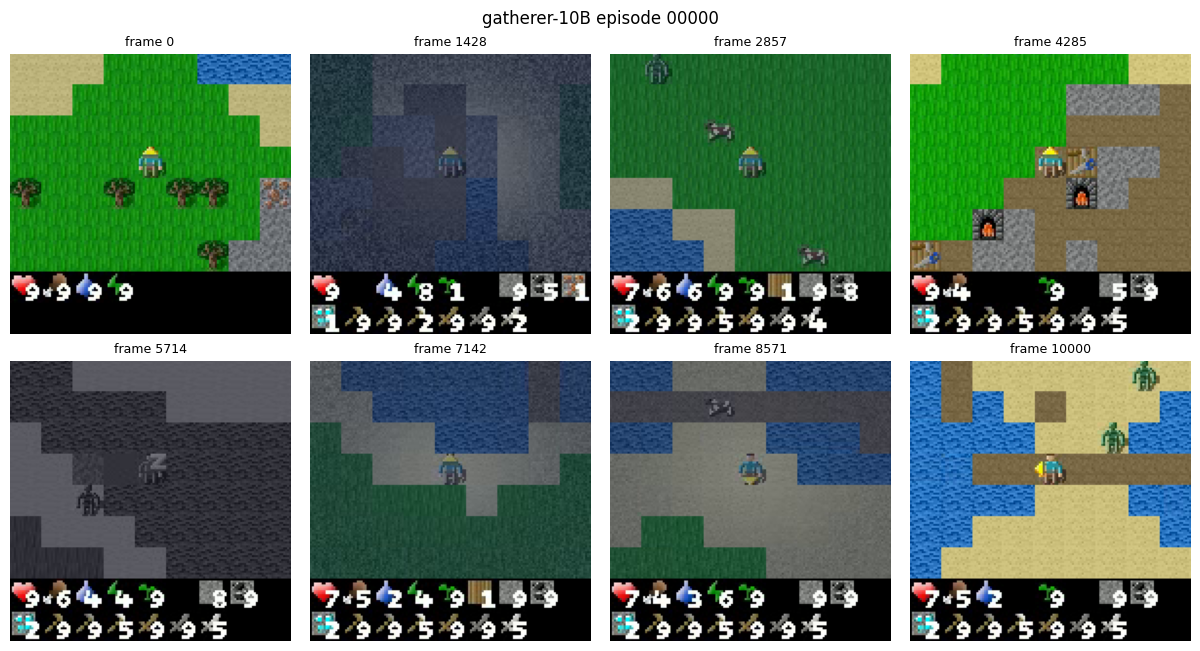

In [4]:
frame_idxs = np.linspace(0, T, 8, dtype=int)
frames = load_video_frames(video_path(EP_DIR, EPISODE), indices=frame_idxs)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), constrained_layout=True)
for ax, i, frame in zip(axes.flat, frame_idxs, frames):
    ax.imshow(frame)
    ax.set_title(f"frame {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{SPLIT} episode {EPISODE}")
plt.show()

### 2.2 Symbolic map and player vitals

The `state` archive contains everything the environment knows — here we render the tile map
with the player position, and the player vitals over time.

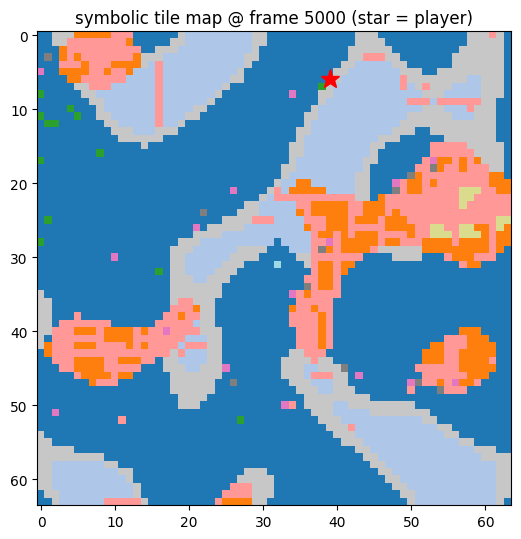

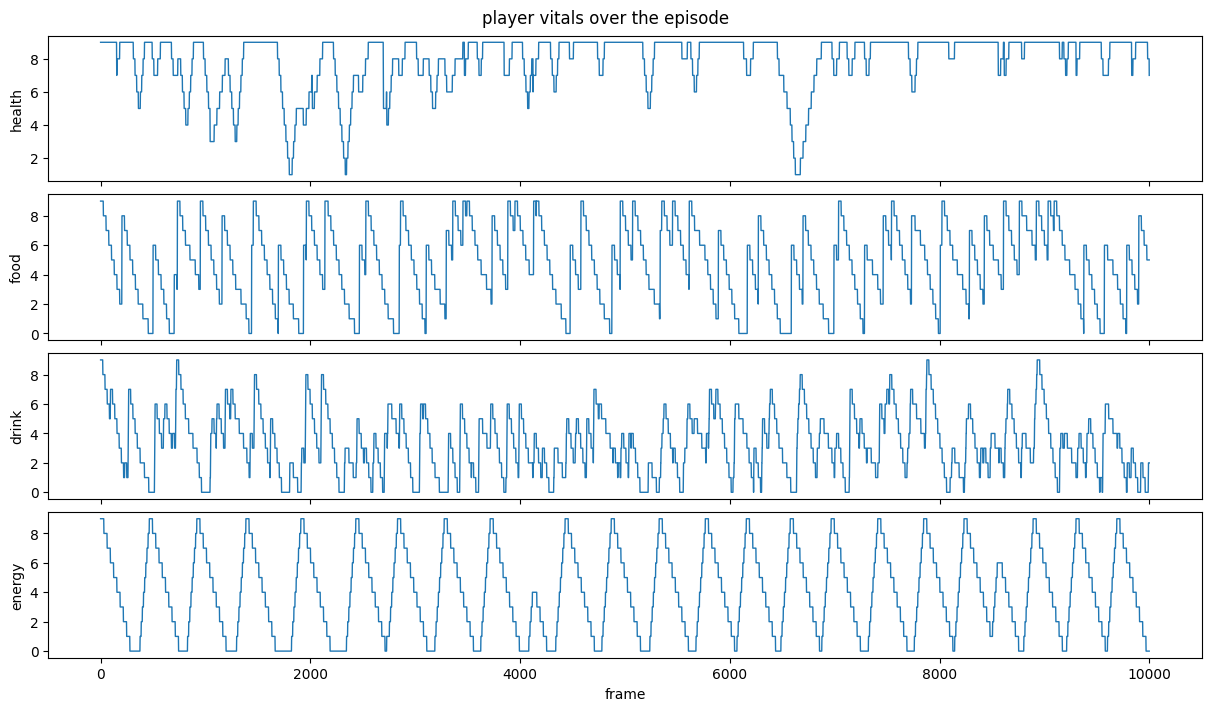

In [5]:
t = T // 2
row, col = state["player_position"][t]

plt.figure(figsize=(5.5, 5.5))
plt.imshow(state["map"][t], cmap="tab20", interpolation="nearest")
plt.plot(col, row, "r*", markersize=14)
plt.title(f"symbolic tile map @ frame {t} (star = player)")
plt.tight_layout()
plt.show()

vitals = ["player_health", "player_food", "player_drink", "player_energy"]
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, key in zip(axes, vitals):
    ax.plot(state[key], lw=1)
    ax.set_ylabel(key.replace("player_", ""))
axes[-1].set_xlabel("frame")
fig.suptitle("player vitals over the episode")
plt.show()

### 2.3 Achievement timeline

`achievements` is a `(T+1, 22)` boolean matrix of the 22 Crafter achievements (an entry stays
True once unlocked), so the frame where each one flips gives the moment it was first achieved.

In [6]:
ach = state["achievements"]
try:
    from craftax.craftax_classic.constants import Achievement
    ach_names = [a.name.lower() for a in Achievement]
except Exception:
    ach_names = [f"achievement_{i}" for i in range(ach.shape[1])]

never = ach.shape[0]
unlocked_at = [int(col.argmax()) if col.any() else never for col in ach.T]

for i in sorted(range(len(ach_names)), key=lambda i: unlocked_at[i]):
    when = f"frame {unlocked_at[i]}" if unlocked_at[i] < never else "not unlocked"
    print(f"{ach_names[i]:<20} {when}")

Loading Craftax-Classic textures from cache.


Textures successfully loaded from cache.
collect_sapling      frame 7
place_plant          frame 8
collect_wood         frame 11
place_table          frame 19
make_wood_sword      frame 20
make_wood_pickaxe    frame 21
collect_stone        frame 23
place_stone          frame 24
place_furnace        frame 26
collect_coal         frame 30
make_stone_pickaxe   frame 42
make_stone_sword     frame 43
collect_iron         frame 52
make_iron_sword      frame 86
collect_drink        frame 93
defeat_skeleton      frame 138
defeat_zombie        frame 154
make_iron_pickaxe    frame 170
eat_cow              frame 203
wake_up              frame 465
collect_diamond      frame 696
eat_plant            frame 702


### 2.4 Caption segments (CrafterCaption)

Each caption covers a 6-frame video segment `(start_frame, end_frame)` — the paper's
$o_{t-4:t+1}$, where the action triggering the rule occurs near the end of the window and the
trailing frame captures its outcome. Below is one segment of the `Kill` rule, rendered as the
frame sequence that goes with the caption, with the action taken at each frame.

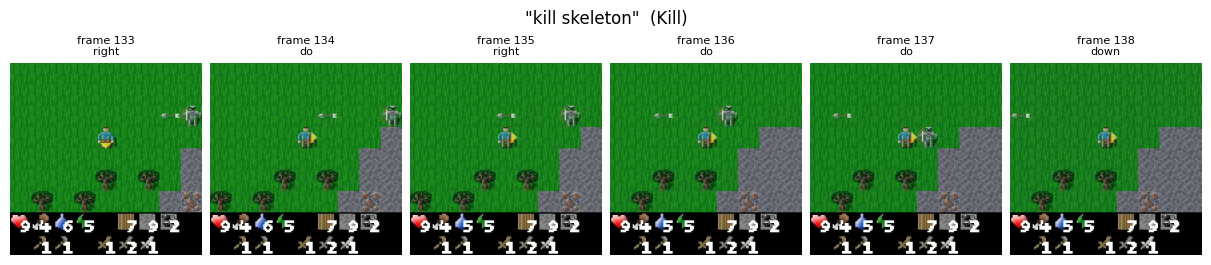

In [7]:
RULE = "Kill"
try:
    from craftax.craftax_classic.constants import Action
    action_names = [a.name.lower() for a in Action]
except Exception:
    action_names = [str(i) for i in range(17)]

(start, end), text, rule = next(c for c in captions if c[2] == RULE)
seg_frames = load_video_frames(video_path(EP_DIR, EPISODE), indices=range(start, end))
seg_actions = [action_names[action_ids[i]] if i < T else "-" for i in range(start, end)]

fig, axes = plt.subplots(1, len(seg_frames), figsize=(12, 2.8), constrained_layout=True)
for ax, i, frame, act in zip(axes, range(start, end), seg_frames, seg_actions):
    ax.imshow(frame)
    ax.set_title(f"frame {i}\n{act}", fontsize=8)
    ax.axis("off")
fig.suptitle(f'"{text}"  ({rule})')
plt.show()

## Part 3 — Working with the full records (`.tar.zst` shards)

The full Gatherer/Survival splits ship as zstandard-compressed tar shards, each covering a
contiguous episode-id range (`metadata/manifest_shards.csv` maps episode ids to shards). Inside,
files follow `playdata_raw/<split>/Craftax-Classic-Symbolic-v1/<field>/<file>`.

You can stream a single file out of a shard without extracting it:

In [8]:
import tarfile


def read_from_shard(shard_path, member_suffix):
    """Return the raw bytes of the first member whose name ends with `member_suffix`."""
    import zstandard
    with open(shard_path, "rb") as fh:
        reader = zstandard.ZstdDecompressor().stream_reader(fh)
        with tarfile.open(fileobj=reader, mode="r|") as tar:
            for member in tar:
                if member.name.endswith(member_suffix):
                    return tar.extractfile(member).read()
    raise KeyError(f"{member_suffix} not found in shard")


SHARD = os.environ.get("CRAFTERDOJO_SHARD")  # path to a downloaded .tar.zst shard
if SHARD:
    raw = read_from_shard(SHARD, "action/action_00000.pkl")
    a_ids, a_null, a_sleep = pickle.loads(raw)
    print("decoded from shard without extraction:", a_ids.shape, a_ids.dtype)
else:
    print("Set the CRAFTERDOJO_SHARD environment variable to a downloaded "
          ".tar.zst shard to run this cell.")

decoded from shard without extraction: (10000,) int32
